In [1]:
"""
main.py
=======
Eksperimen Federated Learning (model terpisah: adapter -> theta -> phi)
dengan pilihan state (top10 / top20 / all), banyak seed, dan komparasi
mode (sim, alt) x agregasi (fedavg, fedprox, pairwise).

Pakai cell per cell (VS Code Interactive / Jupyter) atau jalankan sebagai skrip.
Ubah SELECTION, SEEDS, dan flag RUN_* di bagian konfigurasi.

Output: hasil_fl/sel_<SELECTION>/
"""
import importlib
import os
import re
import shutil
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from dataset import prepare_client_data, DROP_COLS, TARGET

# ============================================================
# 0. KONFIGURASI
# ============================================================
SRC_CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
OUT_ROOT = Path("hasil_fl")

SELECTION = "top10"            # "top10" | "top20" | "all"
SEEDS = (42, 22, 1)

# Urutan state berdasarkan rata-rata F1 test run sebelumnya (rank 1 -> 20)
RANKED_STATES = [
    54, 13, 23, 5, 29, 16, 41, 19, 10, 39,   # top 10
    30, 22, 55, 33, 34, 37, 50, 48, 12, 1,   # rank 11-20
]
TOP_N = {"top10": 10, "top20": 20}

# Hyperparameter eksperimen
COMMON_DIM = 64
N_CLASSES = 2
NUM_ROUNDS = 10
LOCAL_EPOCHS = 5
FEDPROX_MU = 0.01
MAX_PARALLEL = 1               # naikkan (mis. 4) bila RAM cukup
MODES = ("sim", "alt")
AGGS = ("fedavg", "fedprox", "pairwise")
BASELINE = "fedavg"

# Cell opsional
RUN_SMOKE = True               # tes cepat: 2 ronde, 1 epoch
RUN_SINGLE = False             # satu konfigurasi penuh dengan laporan lengkap

RESULT_DIR = OUT_ROOT / f"sel_{SELECTION}"
RESULT_DIR.mkdir(parents=True, exist_ok=True)


In [2]:

# %%
# ============================================================
# 1. SUBSET STATE + MUAT DATA
#    Folder subset dibuat dulu, baru di-scale, sehingga scaler
#    hanya di-fit dari state terpilih.
# ============================================================
def _state_id(path: Path):
    """Nomor state = angka pertama pada nama file/folder. None bila tidak ada."""
    m = re.search(r'\d+', path.stem)
    return int(m.group()) if m else None


def _copy_item(src: Path, dst: Path):
    if src.is_dir():
        shutil.copytree(src, dst)
        return
    try:
        os.link(src, dst)            # hardlink: cepat, tanpa duplikasi
    except OSError:
        shutil.copy2(src, dst)


def build_subset_dir(selection: str) -> Path:
    if selection == "all":
        return SRC_CLIENT_DIR
    wanted = set(RANKED_STATES[:TOP_N[selection]])
    subset_dir = OUT_ROOT / f"_clients_{selection}"
    if subset_dir.exists():
        shutil.rmtree(subset_dir)
    subset_dir.mkdir(parents=True)

    found = set()
    for item in sorted(SRC_CLIENT_DIR.iterdir()):
        sid = _state_id(item)
        if sid is None or sid in wanted:
            _copy_item(item, subset_dir / item.name)
            if sid is not None:
                found.add(sid)
    missing = wanted - found
    if missing:
        sys.exit(f"State tidak ditemukan di {SRC_CLIENT_DIR}: {sorted(missing)}")
    return subset_dir


if not SRC_CLIENT_DIR.is_dir():
    sys.exit(f"Folder dataset tidak ditemukan: {SRC_CLIENT_DIR}")

CLIENT_DIR = build_subset_dir(SELECTION)
clients, scaler, feature_names = prepare_client_data(CLIENT_DIR)

# Pastikan state yang termuat sama persis dengan yang diminta
if SELECTION != "all":
    wanted = set(RANKED_STATES[:TOP_N[SELECTION]])
    loaded = {int(s) for s in clients}
    assert loaded == wanted, (
        f"State termuat tidak sesuai. Kurang: {sorted(wanted - loaded)}, "
        f"lebih: {sorted(loaded - wanted)}")

n_fitur = next(iter(clients.values()))['X_train_t'].shape[1]
assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"

print(f"Seleksi       : {SELECTION}")
print(f"Folder client : {CLIENT_DIR}")
print(f"Jumlah client : {len(clients)}")
print(f"Daftar state  : {sorted(int(s) for s in clients)}")
print(f"Target        : {TARGET}")
print(f"Kolom dibuang : {DROP_COLS}")
print(f"Jumlah fitur  : {n_fitur}")
for i, nama in enumerate(feature_names, 1):
    print(f"{i:>3}. {nama}")

# ---- ringkasan tiap client ----
rows = {st: {
    'n_train': len(c['y_train_t']), 'n_val': len(c['y_val_t']), 'n_test': len(c['y_test_t']),
    'pos_train': int(c['y_train_t'].sum()), 'pos_val': int(c['y_val_t'].sum()),
    'pos_test': int(c['y_test_t'].sum()),
} for st, c in clients.items()}

ringkas = pd.DataFrame(rows).T
ringkas.index.name = 'state'
for s in ('train', 'val', 'test'):
    ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)
total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
for s in ('train', 'val', 'test'):
    total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
ringkas.loc['TOTAL'] = total
print("\nRingkasan per client:")
print(ringkas.to_string())
print("\nscaler.n_samples_seen_ vs total train:", scaler.n_samples_seen_,
      sum(len(c['y_train_t']) for c in clients.values()), "(harus sama)")
ringkas.to_csv(RESULT_DIR / "ringkasan_data.csv")


# %%
# ============================================================
# 2. clients -> fed_data (format yang diminta fl_running1)
# ============================================================
fed_data = {}
for st, c in clients.items():
    fed_data[f"state_{st}"] = {
        "X_train": c["X_train_t"], "y_train": c["y_train_t"],
        "X_val":   c["X_val_t"],   "y_val":   c["y_val_t"],
        "X_test":  c["X_test_t"],  "y_test":  c["y_test_t"],
        "n_features": c["X_train_t"].shape[1],
    }
print("Client:", list(fed_data.keys()))
print("n_features per client:", {k: v["n_features"] for k, v in fed_data.items()})


Seleksi       : top10
Folder client : hasil_fl\_clients_top10
Jumlah client : 10
Daftar state  : [5, 10, 13, 16, 19, 23, 29, 39, 41, 54]
Target        : _michd
Kolom dibuang : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']
Jumlah fitur  : 69
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwalk
 28. diffdres
 29. diffalon
 30. _rfbing6
 31. drnkany6
 32. flushot7
 33. pneuvac4
 34. marital_1
 35. marital_2
 36. marital_3
 37. marital_4
 38. marital_5
 39. marital_6
 40. employ1_1
 41. employ1_2
 42. employ1_3
 43. employ1_4
 44. employ1_5
 45. employ1_6
 46. employ1_7
 47. employ1_8
 48. renthom1_1
 49. renthom1_2
 50. renthom1_3
 51. _imprace_1
 52. _imprace_2
 53. _imprace_3
 54. _imprac

2026-10-20 22:16:14,926	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
INFO :      Starting Flower ServerApp, config: num_rounds=2, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Evaluating initial global parameters
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)
INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      fit progress: (1, 0.6111327119397221, {'accuracy': 0.7600284919571012, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'auc': 0.6023869067899172}, 7.338727099937387)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)


[smoke|sim|fedavg] round 01 | loss=0.6111 acc=0.7600 prec=0.0000 rec=0.0000 f1=0.0000 auc=0.6024 | comm=0.476MB (cum 0.476MB)


INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      fit progress: (2, 0.5488825820241744, {'accuracy': 0.7601230993364767, 'precision': 0.1, 'recall': 0.0003952569169960474, 'f1': 0.0007874015748031496, 'auc': 0.688882685890848}, 8.424446600023657)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 2 round(s) in 8.43s
INFO :      	History (loss, centralized):
INFO :      		round 1: 0.6111327119397221
INFO :      		round 2: 0.5488825820241744
INFO :      	History (metrics, distributed, fit):
INFO :      	{'bytes_down': [(1, 249600.0), (2, 249600.0)],
INFO :      	 'bytes_up': [(1, 249600.0), (2, 249600.0)]}
INFO :      	History (metrics, centralized):
INFO :      	{'accuracy': [(1, 0.7600284919571012), (2, 0.7601230993364767)],
INFO :      	 'auc': [(1, 0.6023869067899172), (2, 0.688882685890848)],
INFO :      	 'f1': [(1, 0.0), (2, 0.0007874015748031496)],
INFO :      	 'precision': 

[smoke|sim|fedavg] round 02 | loss=0.5489 acc=0.7601 prec=0.1000 rec=0.0004 f1=0.0008 auc=0.6889 | comm=0.476MB (cum 0.952MB)
[smoke|sim|fedavg] best val round (by f1) = 2
[0.0, 0.0007874015748031496] {'theta_size_mb': 0.0238037109375, 'total_up_mb': 0.47607421875, 'total_down_mb': 0.47607421875, 'total_mb': 0.9521484375, 'avg_per_round_mb': 0.47607421875, 'avg_per_client_mb': 0.09521484375, 'full_total_mb': 1.64581298828125, 'saving_pct': 42.147227888002966}

################ MODE: sim | top10 | seeds=[42, 22, 1] ################

===== cmp | AGG: fedavg | seed=42 =====


INFO :      Starting Flower ServerApp, config: num_rounds=10, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Evaluating initial global parameters
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)
INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      fit progress: (1, 0.5080308730795704, {'accuracy': 0.7601543209332049, 'precision': 0.35679438058748403, 'recall': 0.026994367624009852, 'f1': 0.047273087216791514, 'auc': 0.7187785322455891}, 7.26005159993656)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)


...

[cmp|alt|pairwise] round 08 | loss=2.8359 acc=0.7116 prec=0.3809 rec=0.3278 f1=0.3514 auc=0.6508 | comm=0.476MB (cum 3.809MB)


INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      fit progress: (9, 3.4084141403697488, {'accuracy': 0.7066761577644723, 'precision': 0.37732990669059835, 'recall': 0.3401805402340556, 'f1': 0.356829226539835, 'auc': 0.645854033712115}, 32.784570800024085)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 10]
INFO :      configure_fit: strategy sampled 10 clients (out of 10)


[cmp|alt|pairwise] round 09 | loss=3.4084 acc=0.7067 prec=0.3773 rec=0.3402 f1=0.3568 auc=0.6459 | comm=0.476MB (cum 4.285MB)


INFO :      aggregate_fit: received 10 results and 0 failures
INFO :      fit progress: (10, 3.9512891743425955, {'accuracy': 0.7051526120023518, 'precision': 0.3720245089102999, 'recall': 0.33332537836559295, 'f1': 0.35017012341733184, 'auc': 0.6481540486864755}, 35.85238100006245)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 10 round(s) in 35.85s
INFO :      	History (loss, centralized):
INFO :      		round 1: 0.5410841959901275
INFO :      		round 2: 0.5415199698258406
INFO :      		round 3: 0.6181831990160307
INFO :      		round 4: 0.7769193146803823
INFO :      		round 5: 1.08825206874863
INFO :      		round 6: 1.523951997092056
INFO :      		round 7: 2.1296757420363948
INFO :      		round 8: 2.8359219274741365
INFO :      		round 9: 3.4084141403697488
INFO :      		round 10: 3.9512891743425955
INFO :      	History (metrics, distributed, fit):
INFO :      	{'agg_weight_client_0': [(1, 0.1302399

[cmp|alt|pairwise] round 10 | loss=3.9513 acc=0.7052 prec=0.3720 rec=0.3333 f1=0.3502 auc=0.6482 | comm=0.476MB (cum 4.761MB)
[cmp|alt|pairwise] best val round (by f1) = 2

               n_seed    test_accuracy   test_precision      test_recall          test_f1         test_auc      testbest_f1 best_round  total_MB
config                                                                                                                                         
sim+fedavg         3  0.7078 ± 0.0029  0.3745 ± 0.0021  0.3152 ± 0.0209  0.3397 ± 0.0119  0.6392 ± 0.0012  0.4143 ± 0.0003      3,3,3      4.76
sim+fedprox        3  0.7066 ± 0.0025  0.3704 ± 0.0028  0.3146 ± 0.0304  0.3374 ± 0.0182  0.6399 ± 0.0026  0.4185 ± 0.0099      3,3,3      4.76
sim+pairwise       3  0.7063 ± 0.0028  0.3634 ± 0.0049  0.2891 ± 0.0091  0.3193 ± 0.0062  0.6395 ± 0.0002  0.4015 ± 0.0063      3,3,3      4.76
alt+fedavg         3  0.7010 ± 0.0025  0.3627 ± 0.0064  0.3305 ± 0.0176  0.3438 ± 0.0125  0.6360 ± 0.0005 

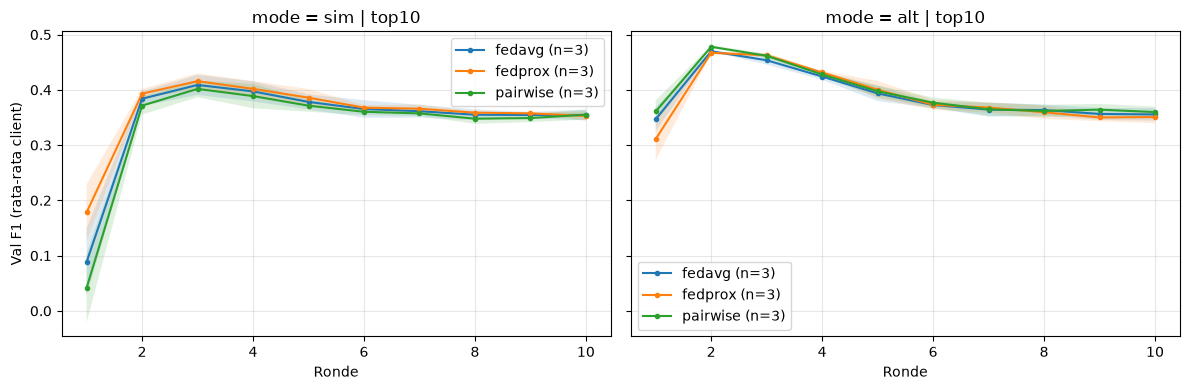

In [3]:

# %%
# ============================================================
# 3. IMPORT RUNNER
# ============================================================
import fl_running1
importlib.reload(fl_running1)            # perubahan file langsung terbaca
from fl_running1 import (
    run_federated, run_comparison, summarize_seeds,
    print_comparison, print_seed_summary,
    export_history_csv, export_per_client_csv,
    export_comparison_csv, export_rounds_comparison_csv,
)


# %%
# ============================================================
# 4. TES CEPAT (sanity check)
# ============================================================
if RUN_SMOKE:
    h_test = run_federated(
        fed_data, name="smoke", common_dim=COMMON_DIM, n_classes=N_CLASSES,
        num_rounds=2, local_epochs=1, mode="sim", aggregation="fedavg",
        verbose_report=False, max_parallel=MAX_PARALLEL,
    )
    print(h_test["f1"], h_test["comm"])


# %%
# ============================================================
# 5. SATU KONFIGURASI PENUH (opsional)
# ============================================================
if RUN_SINGLE:
    history = run_federated(
        fed_data, name="exp", common_dim=COMMON_DIM, n_classes=N_CLASSES,
        num_rounds=NUM_ROUNDS, local_epochs=LOCAL_EPOCHS, batch_size=64, lr=1e-3,
        mode="alt", aggregation="pairwise", epochs_v=3, epochs_u=2,
        select_by="f1", verbose_report=True, max_parallel=MAX_PARALLEL,
    )
    print("\nTEST ronde terakhir:", history["test"])
    print("TEST ronde terbaik :", history.get("test_best"),
          "| best_round =", history.get("best_round"))


# %%
# ============================================================
# 6. KOMPARASI mode x agregasi x seed
# ============================================================
all_hist = {}                 # {mode: {agg: history}}, history["runs"] = semua seed
for mode in MODES:
    print(f"\n################ MODE: {mode} | {SELECTION} | seeds={list(SEEDS)} ################")
    all_hist[mode] = run_comparison(
        fed_data, name="cmp", common_dim=COMMON_DIM,
        aggregations=AGGS, seeds=SEEDS, n_classes=N_CLASSES,
        num_rounds=NUM_ROUNDS, local_epochs=LOCAL_EPOCHS,
        mode=mode, fedprox_mu=FEDPROX_MU, select_by="f1",
        max_parallel=MAX_PARALLEL,
    )


# %%
# ============================================================
# 7. TABEL RINGKASAN (rata-rata ± std antar SEED)
# ============================================================
def _fmt(mu, sd):
    return f"{mu:.4f} ± {sd:.4f}" if not np.isnan(sd) else f"{mu:.4f}"


rows = []
for mode, hs in all_hist.items():
    s_last = summarize_seeds(hs, "test")
    s_best = summarize_seeds(hs, "test_best")
    for agg, h in hs.items():
        runs = h["runs"]
        row = {"config": f"{mode}+{agg}", "n_seed": len(runs)}
        for k in ("accuracy", "precision", "recall", "f1", "auc"):
            row[f"test_{k}"] = _fmt(*s_last[agg][k])
        row["testbest_f1"] = _fmt(*s_best[agg]["f1"])
        row["best_round"] = ",".join(str(r.get("best_round")) for r in runs)
        row["total_MB"] = round(float(np.mean([r["comm"]["total_mb"] for r in runs])), 2)
        rows.append(row)

summary = pd.DataFrame(rows).set_index("config")
print("\n", summary.to_string())

# Selisih F1 (test_best) terhadap baseline pada seed yang sama
print(f"\nSelisih F1 test_best vs {BASELINE} (seed yang sama; positif = lebih baik):")
for mode, hs in all_hist.items():
    if BASELINE not in hs:
        continue
    base = {r["seed"]: r["test_best"]["f1"]
            for r in hs[BASELINE]["runs"] if r.get("test_best")}
    for agg, h in hs.items():
        if agg == BASELINE:
            continue
        d = [r["test_best"]["f1"] - base[r["seed"]]
             for r in h["runs"] if r.get("test_best") and r["seed"] in base]
        if d:
            print(f"  {mode}+{agg:<9} mean {np.mean(d):+.4f} | menang {sum(x > 0 for x in d)}/{len(d)}"
                  f" | per seed {[round(x, 4) for x in d]}")


# %%
# ============================================================
# 8. DETAIL PER CLIENT (seed pertama) + RINGKASAN ANTAR SEED
# ============================================================
for mode, hs in all_hist.items():
    print(f"\n######## {mode} : ronde terbaik (val), seed {SEEDS[0]} ########")
    print_comparison(hs, split="test_best_per_client", baseline=BASELINE)
    if len(SEEDS) > 1:
        print_seed_summary(hs, split="test_best")


# %%
# ============================================================
# 9. EKSPOR CSV  (tiap seed disimpan terpisah)
# ============================================================
for mode, hs in all_hist.items():
    for agg, h in hs.items():
        for r in h["runs"]:
            tag = f"{mode}_{agg}_s{r['seed']}"
            export_history_csv(r, str(RESULT_DIR / f"{tag}_rounds.csv"))
            export_per_client_csv(r, str(RESULT_DIR / f"{tag}_per_client_val.csv"))
            export_per_client_csv(r, str(RESULT_DIR / f"{tag}_per_client_test.csv"),
                                  split="test_per_client")
    export_comparison_csv(hs, str(RESULT_DIR / f"{mode}_compare_test_best.csv"),
                          split="test_best_per_client")
    export_rounds_comparison_csv(hs, str(RESULT_DIR / f"{mode}_compare_rounds.csv"))
summary.to_csv(RESULT_DIR / "summary.csv")


# %%
# ============================================================
# 10. PLOT F1 VALIDASI PER RONDE (rata-rata ± std antar seed)
# ============================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(all_hist), figsize=(6 * len(all_hist), 4),
                         sharey=True, squeeze=False)
for ax, (mode, hs) in zip(axes[0], all_hist.items()):
    for agg, h in hs.items():
        runs = h["runs"]
        L = min(len(r["f1"]) for r in runs)
        arr = np.array([r["f1"][:L] for r in runs], dtype=float)
        mu = arr.mean(axis=0)
        x = runs[0]["round"][:L]
        ax.plot(x, mu, marker="o", ms=3, label=f"{agg} (n={len(runs)})")
        if len(runs) > 1:
            sd = arr.std(axis=0, ddof=1)
            ax.fill_between(x, mu - sd, mu + sd, alpha=0.15)
    ax.set_title(f"mode = {mode} | {SELECTION}")
    ax.set_xlabel("Ronde")
    ax.grid(alpha=.3)
    ax.legend()
axes[0][0].set_ylabel("Val F1 (rata-rata client)")
plt.tight_layout()
plt.savefig(RESULT_DIR / "f1_per_round.png", dpi=150)
plt.show()